# Tutorial 5 — Surface-hopping dynamics with SHARC and X-MACE

Now the model drives real non-adiabatic dynamics: SHARC propagates the nuclei and the
electronic wavefunction, and asks X-MACE for energies, gradients, NACs, SOCs and
dipoles at every time step. We run the same ensemble of trajectories with X-MACE
and with the reference (LVC) model and compare.

You will learn

1. how SHARC and X-MACE talk to each other, and which files a trajectory needs;
2. what goes into `MACE.template`;
3. how to run a single point, a pysharc trajectory and a `sharc.x` trajectory;
4. how to check energy conservation and compare state populations.

**Requirements:** SHARC 4.1 with pysharc, `work/so2.model` from Tutorial 3.
Runtime: about 15 minutes.

In [1]:
import os
import subprocess
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np

import mace  # noqa: F401

TUTORIAL = Path.cwd()
REPO = TUTORIAL.parents[1]
INTERFACE_DIR = REPO / "scripts" / "sharc"  # SHARC_MACE.py and MACE.template
sys.path.insert(0, str(TUTORIAL / "tools"))
import so2_lvc as lvc

WORK = TUTORIAL / "work"
plt.rcParams.update({"figure.dpi": 100})
STATES = [4, 0, 3]
assert lvc.sharc_root() is not None, "set $SHARC (source $SHARC/sharcvars.sh)"
assert (WORK / "so2.model").exists(), "run Tutorial 3 first"

## 1. How the pieces fit together

```
 sharc.x  ──writes QM/QM.in──▶  QM/runQM.sh ─▶ SHARC_MACE.py QM.in ─▶ QM/QM.out   (one process per step)
 pysharc  ──Python call─────▶  SHARC_MACE (stays in memory)                       (driver.py -i MACE)
                                   │
                                   ▼
                   mace.calculators.SharcCalculator   (units, M_S states, phases)
                                   │
                                   ▼
                   ExcitedMACECalculator ─▶ trained model (.model file)
```

`scripts/sharc/SHARC_MACE.py` is a SHARC interface of the "FAST" kind (like SHARC's
LVC and SchNarc/SPaiNN interfaces). SHARC finds it if it is in `$SHARC` (copy or
link it there) or on `PYTHONPATH`; here we put `scripts/sharc` on `PYTHONPATH` for the
SHARC processes. A trajectory directory contains:

| file | content |
|---|---|
| `input` | SHARC's control file: states, time step, surface-hopping options |
| `geom`, `veloc` | initial geometry (bohr) and velocities (bohr per a.u. of time) |
| `QM/MACE.template` | which model and properties to use, and units |
| `QM/MACE.resources` | optional: `modelpath <file>` (instead of `model_file` in the template) |
| `QM/runQM.sh` | only for `sharc.x`: calls `SHARC_MACE.py QM.in` |

**Before you start with pysharc:** SHARC 4.1 has a bug in `source/input_list.f90`
(`stat` is never set to 0, the line is commented out) that can make pysharc lose its
input file once PyTorch is loaded: SHARC stops with `Keyword CHARGE not found`.
Uncomment `stat = 0` in `next_keyword` and rebuild SHARC (see XMACE.md).

## 2. `MACE.template`

In [2]:
template = f"""model_file    {WORK / 'so2.model'}
properties    energy forces nacs socs dipoles
device        cpu
energy_unit   eV
distance_unit Ang
soc_unit      cm-1
"""
print(template)

model_file    ./work/so2.model
properties    energy forces nacs socs dipoles
device        cpu
energy_unit   eV
distance_unit Ang
soc_unit      cm-1



* `model_file`: the trained model (a glob pattern such as `so2_seed*.model` gives a
  committee, whose mean SHARC then uses);
* `properties`: what SHARC gets. `nacs` sends physical NACs (smooth NACs divided by
  the predicted gap); `smooth_nacs` would send the smooth ones; `socs` needs a model
  trained with SOCs;
* `energy_unit`, `distance_unit`: the units of the **training data**; the interface
  converts to atomic units;
* `soc_unit`: the unit of the SOC labels if different from the energies (we trained
  with SOCs in cm⁻¹).

## 3. A single point

Every SHARC interface can be run by hand on a `QM.in` file, which is the quickest
test of a setup. `QM.in` has the geometry, the states and what to compute:

In [3]:
v0 = lvc.read_v0(WORK / "lvc_model" / "V0.txt")
single = WORK / "single_point"
single.mkdir(exist_ok=True)
(single / "MACE.template").write_text(template)
geometry = "\n".join(f"{s} {x:.8f} {y:.8f} {z:.8f}" for s, (x, y, z) in zip(v0["symbols"], v0["coords"]))
(single / "QM.in").write_text(
    f"3\n\n{geometry}\nunit bohr\nstates 4 0 3\ncharge 0 1 0\nsavedir ./save\nstep 0\nh\nsoc\ndm\ngrad\nnacdr\n"
)
env = lvc.sharc_env([str(INTERFACE_DIR), str(REPO)])
result = subprocess.run([sys.executable, str(INTERFACE_DIR / "SHARC_MACE.py"), "QM.in"],
                        cwd=single, env=env, capture_output=True, text=True)
print("exit code", result.returncode)
qm_out = (single / "QM.out").read_text().splitlines()
start = next(i for i, line in enumerate(qm_out) if line.startswith("! 1 Hamiltonian"))
print("\n".join(qm_out[start:start + 3]))
print("...")
diagonal = [float(qm_out[start + 2 + k].split()[2 * k]) for k in range(13)]
print("energies on the diagonal (eV):", np.round(np.array(diagonal) * 27.211386, 3))

exit code 0
! 1 Hamiltonian Matrix (13x13, complex)
13 13
-3.158062644392E-005  0.000000000000E+000  0.000000000000E+000  0.000000000000E+000  0.000000000000E+000  0.000000000000E+000  0.000000000000E+000  0.000000000000E+000 -1.520022620615E-012  4.927826479885E-015 -2.903340699049E-013  1.346928473188E-014 -1.782911274991E-011  1.133895739317E-014  0.000000000000E+000 -1.010988575763E-006  0.000000000000E+000  4.763998313762E-007  0.000000000000E+000  1.636401606760E-006 -1.520022620615E-012 -4.927826479885E-015 -2.903340699049E-013 -1.346928473188E-014 -1.782911274991E-011 -1.133895739317E-014 
...
energies on the diagonal (eV): [-1.000e-03  4.225e+00  4.598e+00  8.405e+00  3.347e+00  4.213e+00
  4.360e+00  3.347e+00  4.213e+00  4.360e+00  3.347e+00  4.213e+00
  4.360e+00]


The 13 diagonal elements are the 4 singlet energies and the 3 triplet energies, each
three times (one per M_S); the off-diagonal elements are the SOCs, in Hartree.

## 4. An ensemble of trajectories: X-MACE against the reference

We draw 8 initial conditions from the Wigner distribution (with a seed not used for
the training data), start every trajectory in S1 (MCH state 2) and propagate it for
100 fs, once with the LVC model and once with X-MACE. The SHARC options
(`work/sharc_lvc/TRAJ_0/input`):

* `surf sharc` — surface hopping in the diagonal basis (energies + SOCs
  diagonalised), which allows intersystem crossing;
* `coupling nacdr` and `gradcorrect` — use NACs for the wavefunction propagation and
  for the gradients of the diagonal states;
* `ekincorrect parallel_vel`, `decoherence_scheme edc` — standard energy conservation
  at hops and decoherence correction;
* `nophases_from_interface` — X-MACE keeps the coupling signs continuous itself.

Eight trajectories are far too few for converged populations (use ≥ 100 in
research), but enough to see whether the model behaves like the reference.

In [4]:
initial = lvc.wigner_sample(v0, 8, seed=5)
lvc_files = {name: (WORK / "lvc_model" / name).read_text() for name in ("LVC.template", "V0.txt", "LVC.resources")}
mace_files = {"MACE.template": template}

timing = {}
for label, files, interface in (("lvc", lvc_files, "LVC"), ("mace", mace_files, "MACE")):
    start = time.time()
    for i in range(8):
        directory = lvc.write_trajectory(
            WORK / f"sharc_{label}" / f"TRAJ_{i}", initial["coords"][i], initial["velocities"][i],
            v0["masses"], files, tmax=100.0, stepsize=0.5, state=2, seed=1000 + i,
        )
        lvc.run_pysharc(directory, interface, extra_paths=[str(INTERFACE_DIR), str(REPO)])
    timing[label] = time.time() - start
    print(f"{label}: 8 trajectories in {timing[label]:.0f} s")

lvc: 8 trajectories in 185 s


mace: 8 trajectories in 448 s


## 5. Analysis

### Energy conservation

The total energy of every trajectory should be conserved; hops conserve it by
rescaling the velocities. A drift points to a model that is not smooth (or a too
large time step). `output.lis` has the energies per step.

Both ensembles show the same picture: smooth curves between hops, and small steps
(up to ~10 meV) at some hops. The steps appear with the exact LVC model too, so they
come from SHARC's hopping algorithm at this time step, not from the ML model. A
model problem would show up as a steady drift, or as a trajectory whose energy
differs from the others.

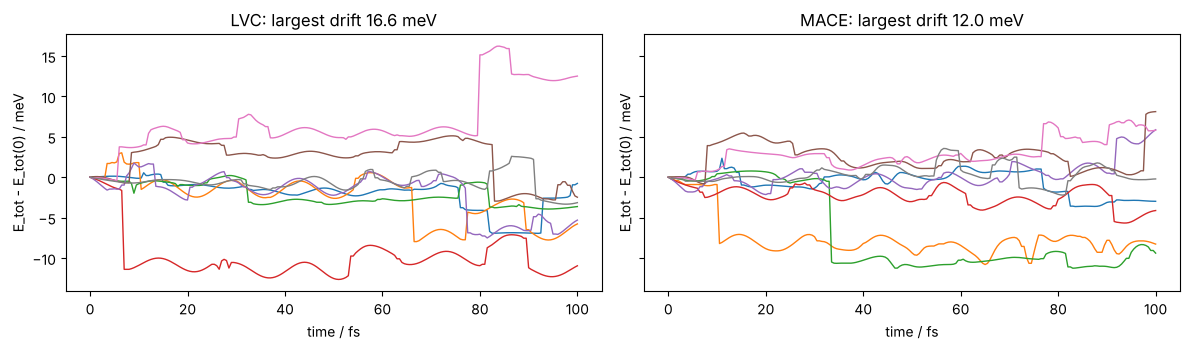

In [5]:
outputs = {label: [lvc.read_output_lis(WORK / f"sharc_{label}" / f"TRAJ_{i}") for i in range(8)] for label in ("lvc", "mace")}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, label in zip(axes, ("lvc", "mace")):
    for out in outputs[label]:
        ax.plot(out["time"], (out["etot"] - out["etot"][0]) * 1000, lw=1)
    drift = max(np.ptp(o["etot"]) for o in outputs[label]) * 1000
    ax.set(title=f"{label.upper()}: largest drift {drift:.1f} meV", xlabel="time / fs", ylabel="E_tot - E_tot(0) / meV")
plt.tight_layout()

### Populations

SHARC reports the active state in the diagonal basis and the MCH (spin-free) state
with the largest weight in it. Counting the trajectories whose active state is a
singlet or a triplet (MCH, M_S-resolved index → multiplicity) gives the *classical*
populations:

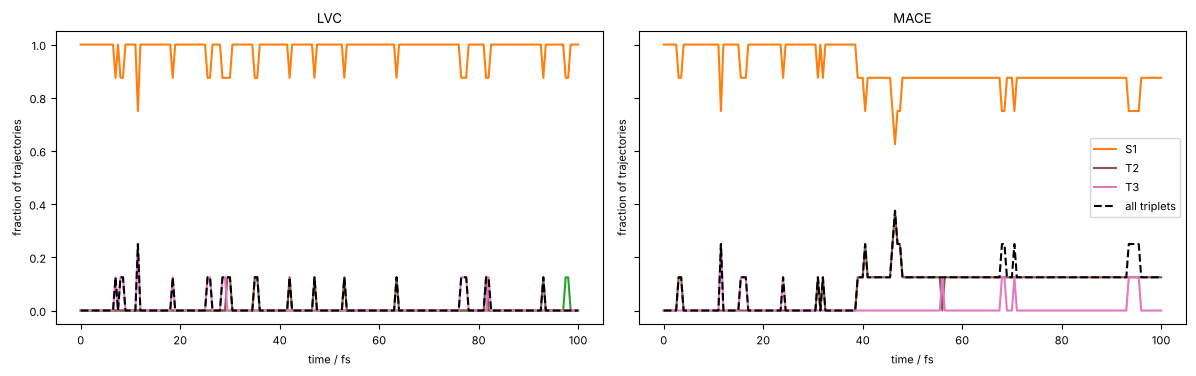

In [6]:
from mace.modules.spin_states import ms_resolved_map

multiplicity = lvc.mch_multiplicity(STATES)  # per M_S-resolved MCH state
spatial = np.zeros(13, dtype=int)  # M_S-resolved MCH index -> spatial state
for k, components in enumerate(ms_resolved_map(STATES)):
    for index, _ in components:
        spatial[index] = k

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
names = ["S0", "S1", "S2", "S3", "T1", "T2", "T3"]
for ax, label in zip(axes, ("lvc", "mace")):
    states_t = np.array([spatial[o["state_mch"] - 1] for o in outputs[label]])  # [traj, time]
    t = outputs[label][0]["time"]
    for s in range(7):
        population = (states_t == s).mean(axis=0)
        if population.max() > 0:
            ax.plot(t, population, label=names[s], color=f"C{s}")
    triplet = (multiplicity[np.array([o["state_mch"] - 1 for o in outputs[label]])] == 3).mean(axis=0)
    ax.plot(t, triplet, color="k", ls="--", label="all triplets")
    ax.set(title=label.upper(), xlabel="time / fs", ylabel="fraction of trajectories")
axes[1].legend(fontsize=8)
plt.tight_layout()

How to read these plots:

* Both ensembles stay mostly in S1 for 100 fs: intersystem crossing in SO2 takes
  hundreds of femtoseconds, so only a few trajectories reach a triplet in this short
  window.
* The short spikes are not real hops. The active state is a *diagonal* (spin-mixed)
  state; where S1 and a triplet are nearly degenerate, SOC mixes them strongly and
  the MCH state with the largest weight flips back and forth.
* With the same initial conditions and random seeds, the two ensembles start
  identically and diverge once a trajectory hops at a different time. Surface hopping
  is stochastic, so only averages over many trajectories (≥ 100) and longer times
  can be compared quantitatively. Eight trajectories only show that the model gives
  the same qualitative behaviour as the reference.

**Timing:** the ML model costs a fraction of a second per step on a CPU (`timing`
above includes Python start-up). For a real molecule, the reference method would take
minutes to hours per step.

In [7]:
print({k: f"{v / 8:.0f} s per 100-fs trajectory" for k, v in timing.items()})

{'lvc': '23 s per 100-fs trajectory', 'mace': '56 s per 100-fs trajectory'}


## 6. The same with `sharc.x`

Without pysharc, SHARC's Fortran program calls the interface as a separate process
at every step through `QM/runQM.sh`. This is slower (the model is loaded every step)
but works everywhere. The interface stores the previous couplings in the save
directory (`restart/mace_phases.<step>`), so their signs stay continuous between the
separate processes. A short check that both routes give the same trajectory:

In [8]:
directory = lvc.write_trajectory(
    WORK / "sharc_x" / "TRAJ_0", initial["coords"][0], initial["velocities"][0], v0["masses"],
    {
        "MACE.template": template,
        "runQM.sh": f"cd QM\nexport PYTHONPATH={INTERFACE_DIR}:{REPO}:$PYTHONPATH\n"
                    f"{sys.executable} {INTERFACE_DIR / 'SHARC_MACE.py'} QM.in >> QM.log 2>> QM.err\n",
    },
    tmax=5.0, stepsize=0.5, state=2, seed=1000,
)
start = time.time()
subprocess.run([str(lvc.sharc_root() / "bin" / "sharc.x"), "input"], cwd=directory, env=env, check=True, capture_output=True)
print(f"sharc.x: 10 steps in {time.time() - start:.0f} s")
x = lvc.read_output_lis(directory)
p = outputs["mace"][0]
n = len(x["time"])
print("largest difference in E_tot to the pysharc run (eV):", np.abs(x["etot"] - p["etot"][:n]).max())

sharc.x: 10 steps in 53 s
largest difference in E_tot to the pysharc run (eV): 1.000000000139778e-06


## 7. Practical advice

* **Validate before production.** Compare a few trajectories (or at least single
  points along them) with the reference method, as above.
* **Watch for extrapolation.** Sudden energy drifts or unphysical geometries mean the
  trajectory left the training data. A committee (several models, `model_file`
  with a glob pattern) gives an uncertainty: add reference calculations where the
  models disagree and retrain (active learning, Tutorial 6).
* **States:** the SHARC `nstates` line may ask for fewer states per multiplicity
  than the model has. Asking for more fails with a clear message.
* **Units:** `energy_unit`, `distance_unit`, `soc_unit` describe the training data.
  A wrong `soc_unit` scales all SOCs by a large factor and changes ISC rates.
* **Errors from the interface** appear in `QM/QM.err` (sharc.x) or on the terminal
  (pysharc); SHARC's own messages are in `output.log`.

**Next:** [Tutorial 6](06_more_models_and_data.ipynb) covers the autoencoder model,
missing labels, legacy data, other multiplicities, committees and the Python API.